# 06 · Análisis exploratorio (EDA): donantes, calidad de las células y composición

Tres bloques:

1. **Donantes.** ¿Encajan Thal, Braak y CERAD con el ADNC? ¿Cómo se reparte el CPS? ¿Qué confusores van de la mano
   de la clase? Todo se cuenta **por donante** (una fila por donante), nunca por célula.
2. **Calidad de las células (QC).** Recuentos, genes detectados y % mitocondrial por tipo celular; qué células
   serían atípicas; si la calidad cambia con la clase.
3. **Técnicas y composición.** Ensayo y muestras por donante; composición de subtipos dentro de cada tipo celular.

Solo lee los metadatos (`obs`) y el UMAP precalculado: no carga la matriz de expresión, así que es rápido.

**Ejecución:** `jupyter nbconvert --to notebook --execute --inplace notebooks\06_eda.ipynb`

In [1]:
import json
import sys
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tfm import data
from tfm import eda as EDA
from tfm.config import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid", context="notebook")

cfg = load_config(ROOT)
COL = cfg["columns"]
DON, LAB, CT = COL["donor"], COL["label"], COL["cell_type"]
ORDEN, TODAS = cfg["labels"]["classification"], cfg["labels"]["all"]
TABLAS, FIGS = cfg["paths"]["tables"], cfg["paths"]["figures"]
PALETA = dict(zip(TODAS, ["#9e9e9e", "#4daf4a", "#ff7f00", "#e41a1c"]))
CPS = "Continuous Pseudo-progression Score"

def guardar(df, nombre):
    df.to_csv(TABLAS / f"eda_{nombre}.csv", encoding="utf-8"); return df

def guardar_fig(fig, nombre):
    fig.savefig(FIGS / f"eda_{nombre}.png", dpi=150, bbox_inches="tight")

obs, _, _, _, _ = data.read_obs_var(cfg["paths"]["subset"])
with h5py.File(cfg["paths"]["subset"], "r") as f:
    umap = f["obsm"]["X_umap"][:] if "X_umap" in f["obsm"] else None

donantes = data.get_donor_table(obs, DON, expected=cfg["donor_level_expected"])
donantes["edad_exacta"], donantes["edad_censurada_80"] = EDA.exact_age(donantes["development_stage"])
d75 = donantes[donantes[LAB].isin(ORDEN)].copy()
print(f"{len(donantes)} donantes ({len(d75)} sin Reference) | {len(obs):,} células")

80 donantes (75 sin Reference) | 24,000 células


## 1. Donantes

### 1.1 Patología: ¿encaja con el ADNC?

El ADNC (criterios NIA-AA) se **calcula** a partir de tres medidas: Thal (extensión del amiloide, A), Braak
(extensión de los ovillos de tau, B) y CERAD (densidad de placas neuríticas, C). Si los datos son coherentes, las
tres deberían crecer con la clase. Es una comprobación de los datos, no un hallazgo: por eso son variables
**prohibidas** como características.

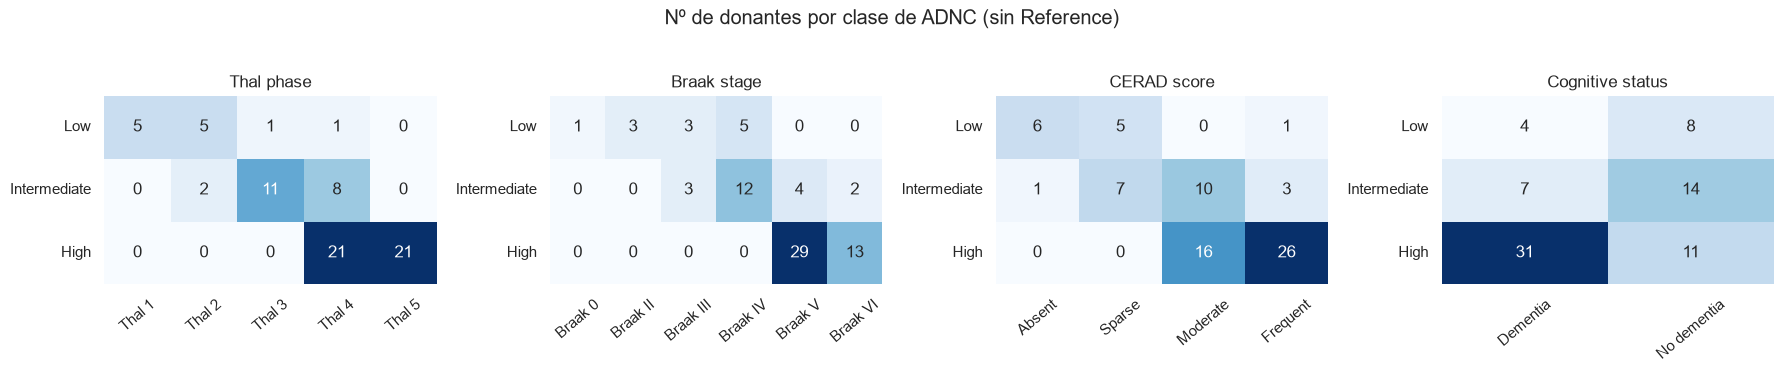

In [2]:
pato = ["Thal phase", "Braak stage", "CERAD score", "Cognitive status"]
fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, c in zip(axs, pato):
    t = pd.crosstab(d75[LAB].astype(str), d75[c].astype(str)).reindex(ORDEN)
    num = EDA.ordinal(pd.Series(t.columns))
    if num.notna().all():
        t = t[t.columns[np.argsort(num.values)]]
    elif c == "CERAD score":
        t = t[[k for k in EDA.CERAD if k in t.columns]]
    guardar(t, f"patologia_{c.split()[0].lower()}")
    sns.heatmap(t, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(c); ax.set_ylabel(""); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40)
    ax.tick_params(axis="y", rotation=0)
fig.suptitle("Nº de donantes por clase de ADNC (sin Reference)", y=1.03)
fig.tight_layout(); guardar_fig(fig, "patologia_vs_adnc"); plt.show()

### 1.2 CPS y edad por clase

El CPS (0 a 1) resume la patología cuantitativa: debería crecer con el ADNC, solapándose entre clases vecinas.
La edad exacta sale de `development_stage`; los marcados con × son "80 o más años" (dato censurado: solo sabemos
que tienen al menos 80).

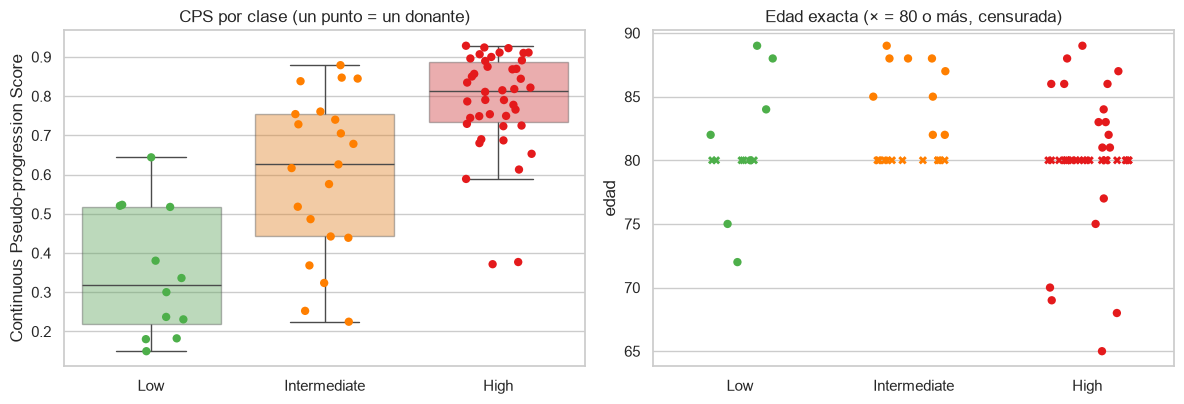

Donantes con edad censurada (80+): {'Low': 5, 'Intermediate': 12, 'High': 24}


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=d75, x=LAB, y=CPS, order=ORDEN, palette=PALETA, ax=axs[0], fliersize=0, boxprops={"alpha": 0.4})
sns.stripplot(data=d75, x=LAB, y=CPS, order=ORDEN, palette=PALETA, ax=axs[0], size=6, jitter=0.2)
axs[0].set_title("CPS por clase (un punto = un donante)"); axs[0].set_xlabel("")
for censura, marca in [(False, "o"), (True, "X")]:
    sub = d75[d75["edad_censurada_80"] == censura]
    sns.stripplot(data=sub, x=LAB, y="edad_exacta", order=ORDEN, palette=PALETA, ax=axs[1], size=6, jitter=0.25,
                  marker=marca)
axs[1].set_title("Edad exacta (× = 80 o más, censurada)"); axs[1].set_xlabel(""); axs[1].set_ylabel("edad")
fig.tight_layout(); guardar_fig(fig, "cps_edad"); plt.show()
print("Donantes con edad censurada (80+):", d75.groupby(LAB, observed=True)["edad_censurada_80"].sum().reindex(ORDEN).to_dict())

### 1.3 Contrastes por donante: ¿qué va de la mano del ADNC?

Para cada variable, un contraste entre las tres clases (Kruskal-Wallis si se puede ordenar, chi-cuadrado si no) y
su correlación con el CPS. Con 75 donantes y casillas pequeñas los p-valores del chi-cuadrado son aproximados
(columna `esperado_min`: por debajo de 5, poco fiables). Se corrige por comparaciones múltiples (Benjamini-Hochberg)
**solo entre los confusores**: la patología se espera asociada por construcción.

In [4]:
confusores = ["edad_exacta", "Age at death", "sex", "APOE4 status", "PMI", "Years of education", "self_reported_ethnicity",
              "LATE-NC stage", "Lewy body disease pathology", "Microinfarct pathology"]
cps = d75[CPS].astype(float)
asoc = EDA.association_table(d75, pato + [CPS] + confusores, LAB, ORDEN, cps=cps)
asoc["grupo"] = np.where(asoc.index.isin(confusores), "confusor", "patología / clínica")
m = asoc["grupo"] == "confusor"
asoc.loc[m, "p_BH"] = multipletests(asoc.loc[m, "p"], method="fdr_bh")[1]
cols = ["grupo", "tipo", "contraste", "estadistico", "p", "p_BH", "efecto", "rho_cps", "p_rho_cps", "esperado_min", "n_donantes"]
asoc = guardar(asoc[[c for c in cols if c in asoc.columns]], "asociaciones_donante")
display(asoc.round(4))

,grupo,tipo,contraste,estadistico,p,p_BH,efecto,rho_cps,p_rho_cps,esperado_min,n_donantes
variable,,,,,,,,,,,
Thal phase,patología / clínica,ordenada,Kruskal-Wallis,49.2856,0.0000,NaN,rho con clase = 0.82,0.6519,0.0000,NaN,75
Braak stage,patología / clínica,ordenada,Kruskal-Wallis,45.1931,0.0000,NaN,rho con clase = 0.78,0.6824,0.0000,NaN,75
CERAD score,patología / clínica,ordenada,Kruskal-Wallis,36.3415,0.0000,NaN,rho con clase = 0.70,0.5899,0.0000,NaN,75
Cognitive status,patología / clínica,categórica,chi-cuadrado,12.2874,0.0021,NaN,V de Cramér = 0.40,NaN,NaN,5.28,75
Continuous Pseudo-progression Score,patología / clínica,ordenada,Kruskal-Wallis,33.0589,0.0000,NaN,rho con clase = 0.66,1.0000,0.0000,NaN,75
edad_exacta,confusor,ordenada,Kruskal-Wallis,3.3660,0.1858,0.4645,rho con clase = -0.14,-0.0922,0.4314,NaN,75
Age at death,confusor,ordenada,Kruskal-Wallis,1.3134,0.5186,0.6920,rho con clase = 0.05,-0.1570,0.1785,NaN,75
sex,confusor,categórica,chi-cuadrado,2.7649,0.2510,0.5019,V de Cramér = 0.19,NaN,NaN,4.64,75
APOE4 status,confusor,categórica,chi-cuadrado,10.7143,0.0047,0.0471,V de Cramér = 0.38,NaN,NaN,4.00,75


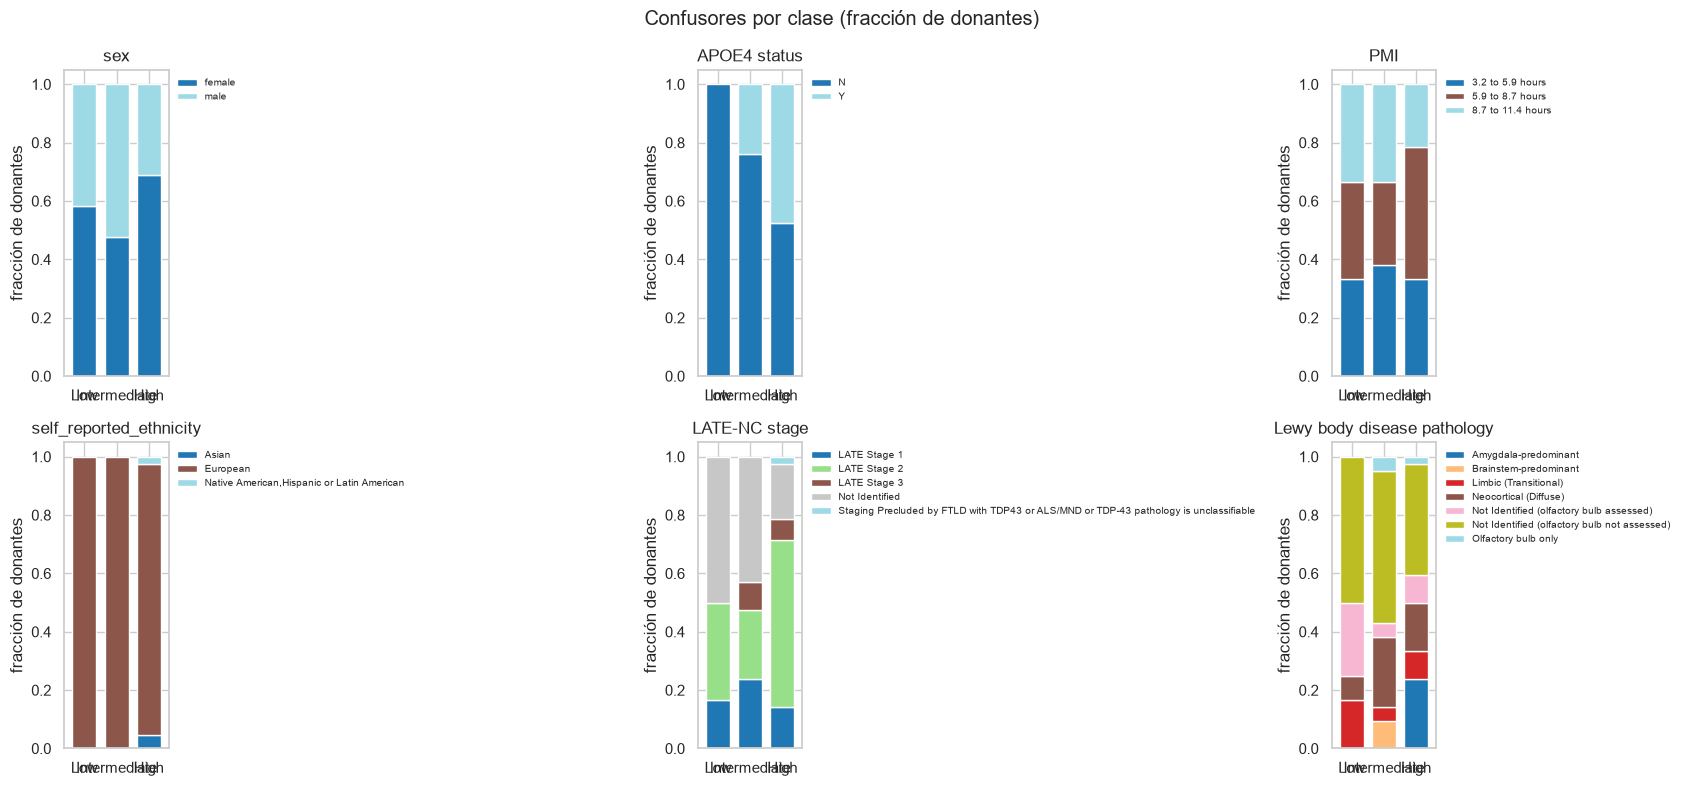

In [5]:
cat = ["sex", "APOE4 status", "PMI", "self_reported_ethnicity", "LATE-NC stage", "Lewy body disease pathology"]
fig, axs = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axs.ravel(), cat):
    t = pd.crosstab(d75[LAB].astype(str), d75[c].astype(str), normalize="index").reindex(ORDEN)
    t.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", width=0.75, legend=False)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("fracción de donantes"); ax.tick_params(axis="x", rotation=0)
    ax.legend(fontsize=7, bbox_to_anchor=(1, 1), frameon=False)
fig.suptitle("Confusores por clase (fracción de donantes)")
fig.tight_layout(); guardar_fig(fig, "confusores"); plt.show()

## 2. Calidad de las células (QC)

Métricas por célula: `total_counts` (moléculas de ARN detectadas), `n_genes` (genes distintos detectados) y
`pct_counts_mt` (% de recuentos de genes mitocondriales). En núcleos, el ARN mitocondrial debería ser casi nulo:
un porcentaje alto sugiere contaminación del citoplasma.

El SEA-AD ya aplicó su propio QC, y el grupo no vuelve a filtrar. Aquí **miramos**, no filtramos.

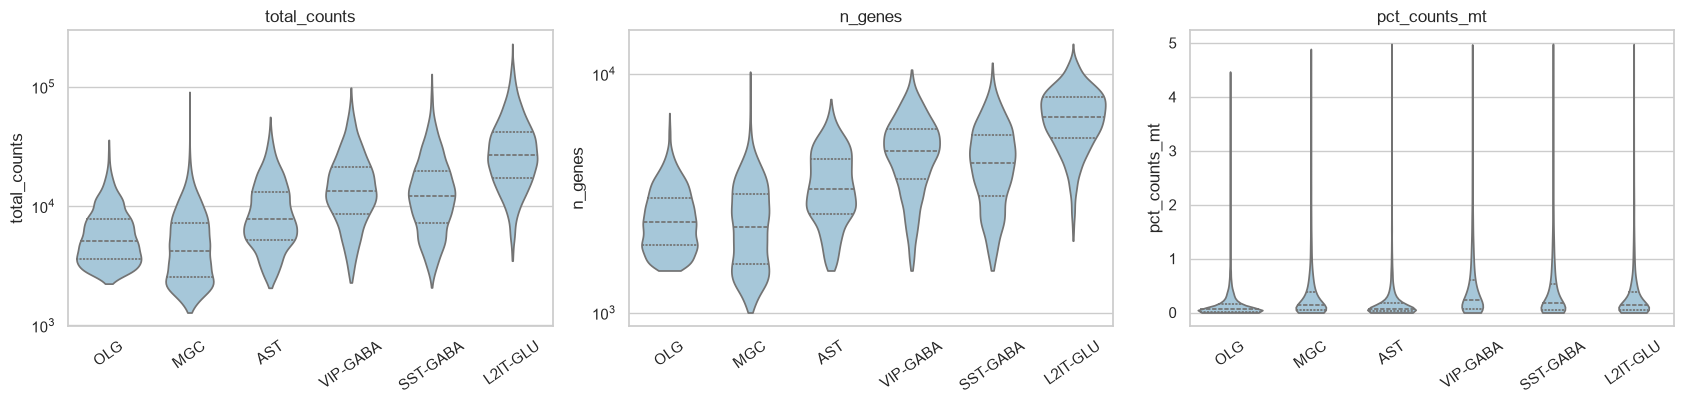

cell_type_abbr                OLG           MGC           AST      VIP-GABA       SST-GABA       L2IT-GLU
total_counts  count   4000.000000   4000.000000   4000.000000   4000.000000    4000.000000    4000.000000
              mean    6274.318500   5469.729750  10025.711500  16744.701500   15510.502000   33215.796500
              std     3731.829591   4202.115069   6936.853866  11953.732014   12478.284673   23882.076990
              min     2239.000000   1282.000000   2065.000000   2289.000000    2080.000000    3486.000000
              5%      2760.950000   1766.850000   3019.950000   4151.300000    3787.950000    9041.400000
              50%     5100.000000   4240.000000   7773.500000  13423.000000   12080.500000   26707.500000
              95%    13316.150000  12882.100000  23748.550000  40540.900000   39304.350000   79650.200000
              max    35784.000000  90334.000000  55729.000000  98003.000000  127554.000000  228258.000000
n_genes       count   4000.000000   4000.000000   4000.000000   4000.000000    4000.000000    4000.000000
              mean    2543.974500   2457.994000   3510.994000   4797.794500    4389.174750    6664.063750
              std      784.970661   1022.335475   1209.663178   1628.886960    1669.089324    1847.182169
              min     1501.000000   1001.000000   1501.000000   1501.000000    1502.000000    2001.000000
              5%      1587.000000   1222.900000   1784.950000   2200.000000    2002.900000    3693.750000
              50%     2386.000000   2280.500000   3293.500000   4769.500000    4245.500000    6616.000000
              95%     3974.050000   4267.100000   5658.150000   7615.200000    7373.650000    9740.400000
              max     6843.000000  10199.000000   7832.000000  10404.000000   11113.000000   13335.000000
pct_counts_mt count   4000.000000   4000.000000   4000.000000   4000.000000    4000.000000    4000.000000
              mean       0.145174      0.336076      0.193141      0.507475       0.436285       0.337002
              std        0.273536      0.541137      0.408588      0.723505       0.670864       0.568824
              min        0.000000      0.000000      0.000000      0.000000       0.000000       0.000000
              5%         0.000000      0.000000      0.000000      0.007130       0.000000       0.004497
              50%        0.057912      0.145881      0.068349      0.237225       0.174705       0.136211
              95%        0.555736      1.336000      0.777616      1.989973       1.777205       1.408449
              max        4.468476      4.888614      4.981274      4.971456       4.982483       4.977288

In [6]:
qc = ["total_counts", "n_genes", "pct_counts_mt"]
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, m_ in zip(axs, qc):
    sns.violinplot(data=obs, x=CT, y=m_, ax=ax, cut=0, inner="quartile", log_scale=(m_ != "pct_counts_mt"), color="#9ecae1")
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35); ax.set_title(m_)
fig.tight_layout(); guardar_fig(fig, "qc_por_tipo"); plt.show()
guardar(obs.groupby(CT, observed=True)[qc].describe(percentiles=[0.05, 0.5, 0.95]).T, "qc_resumen_por_tipo")

### 2.1 ¿Cuántas células serían atípicas?

Dos criterios:

- **Adaptativo (3 MAD):** una célula es atípica si está a más de 3 desviaciones absolutas medianas de la mediana
  de **su** tipo celular (en escala log). Cada tipo tiene su rango normal.
- **Fijo (el del repositorio del grupo, que no se aplicó):** `n_genes` entre 2.000 y 6.000 y `total_counts` ≤ 250.000.

El criterio fijo castiga a los tipos con más o menos ARN: por eso se prefiere el adaptativo.

In [7]:
marcas, limites = EDA.mad_outliers(obs, qc, CT, k=3)
guardar(limites, "qc_limites_mad")
obs_q = obs[[CT, LAB, DON]].copy()
obs_q["atipica_MAD"] = marcas.any(axis=1)
obs_q["fuera_umbral_fijo"] = ~obs["n_genes"].between(2000, 6000) | (obs["total_counts"] > 250000)
frac = obs_q.groupby(CT, observed=True)[["atipica_MAD", "fuera_umbral_fijo"]].mean().mul(100).round(1)
frac_clase = obs_q[obs_q[LAB].isin(ORDEN)].groupby(LAB, observed=True)[["atipica_MAD", "fuera_umbral_fijo"]].mean().mul(100).round(1).reindex(ORDEN)
guardar(frac, "qc_atipicas_por_tipo"); guardar(frac_clase, "qc_atipicas_por_clase")
print("% de células por tipo celular"); display(frac)
print("% de células por clase"); display(frac_clase)
print("Por métrica (3 MAD, % de células):", marcas.mean().mul(100).round(1).to_dict())

% de células por tipo celular


,atipica_MAD,fuera_umbral_fijo
cell_type_abbr,,
OLG,10.5,30.8
MGC,9.5,41.3
AST,12.6,12.1
VIP-GABA,7.8,25.6
SST-GABA,9.9,22.5
L2IT-GLU,10.7,62.4


% de células por clase


,atipica_MAD,fuera_umbral_fijo
ADNC,,
Low,5.6,30.1
Intermediate,8.6,29.2
High,18.4,28.0


Por métrica (3 MAD, % de células): {'total_counts': 0.1, 'n_genes': 0.3, 'pct_counts_mt': 10.0}


### 2.2 ¿Cambia la calidad con la clase?

Si los donantes High tuvieran sistemáticamente peor calidad de ARN (por ejemplo, por más tiempo post mortem o
tejido más degradado), un modelo podría aprender la calidad en lugar de la enfermedad. Calculamos la **mediana por
donante** dentro de cada tipo y comparamos las tres clases (Kruskal-Wallis entre donantes, no entre células).

kruskal_H      p  rho_con_clase  mediana_Low  mediana_Intermediate  mediana_High   p_BH
tipo     metrica                                                                                               
OLG      total_counts       0.535  0.765          0.042     6534.500              5743.000      6139.000  0.862
         n_genes            0.835  0.659          0.049     2679.750              2646.000      2736.750  0.847
         pct_counts_mt      5.419  0.067          0.273        0.085                 0.097         0.134  0.150
MGC      total_counts       0.533  0.766          0.064     5105.000              5027.000      5455.250  0.862
         n_genes            1.238  0.539          0.080     2600.250              2569.000      2688.750  0.808
         pct_counts_mt     10.921  0.004          0.376        0.139                 0.125         0.300  0.040
AST      total_counts       0.047  0.977         -0.020    10089.000              9406.000      9990.000  0.991
         n_genes            0.018  0.991         -0.010     3744.000              3742.500      3784.000  0.991
         pct_counts_mt      4.522  0.104          0.237        0.062                 0.059         0.110  0.188
VIP-GABA total_counts       6.974  0.031         -0.302    17035.500             14009.500     11121.250  0.092
         n_genes            8.007  0.018         -0.327     5121.750              4697.000      4195.000  0.074
         pct_counts_mt      5.567  0.062          0.273        0.210                 0.264         0.387  0.150
SST-GABA total_counts       0.904  0.637         -0.103    11434.250             11277.000     10648.000  0.847
         n_genes            1.684  0.431         -0.148     4057.750              3840.000      3685.000  0.705
         pct_counts_mt      4.911  0.086          0.253        0.292                 0.329         0.494  0.172
L2IT-GLU total_counts      10.590  0.005         -0.373    30650.250             30868.000     23398.000  0.040
         n_genes           10.021  0.007         -0.363     6859.250              6916.000      5966.500  0.040
         pct_counts_mt      7.763  0.021          0.310        0.145                 0.150         0.283  0.074

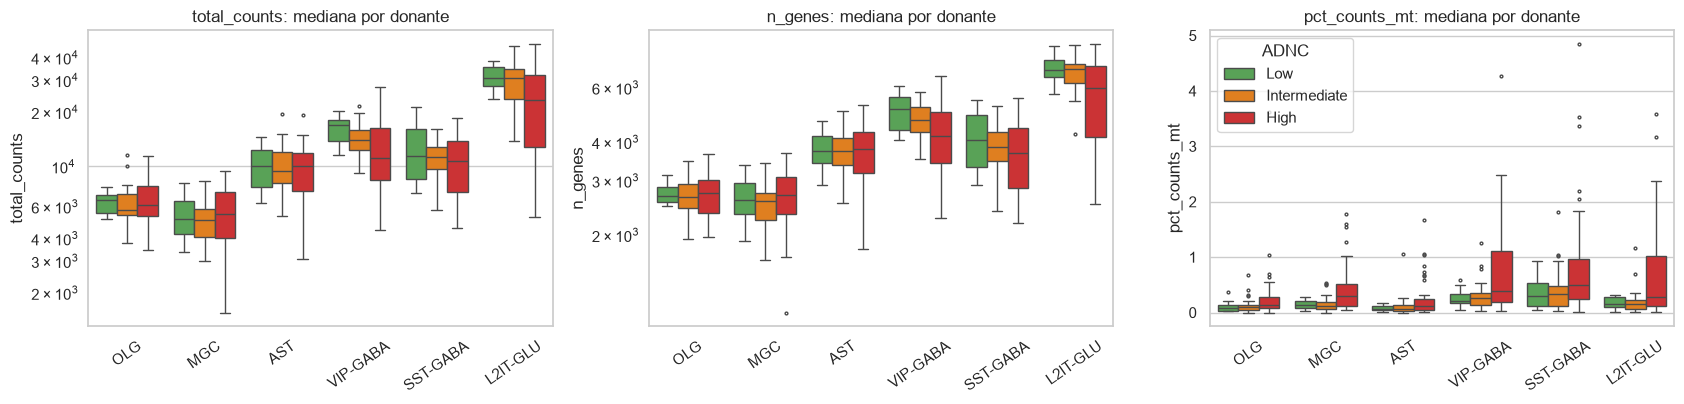

In [8]:
med = EDA.donor_medians(obs[obs[LAB].isin(ORDEN)], qc, DON, CT)
med[LAB] = med[DON].map(donantes[LAB]).astype(str)
filas = []
for t, g in med.groupby(CT, observed=True):
    for m_ in qc:
        h, p = stats.kruskal(*[g.loc[g[LAB] == c, m_] for c in ORDEN])
        rho = stats.spearmanr(g[LAB].map({c: i for i, c in enumerate(ORDEN)}), g[m_])[0]
        filas.append({"tipo": t, "metrica": m_, "kruskal_H": h, "p": p, "rho_con_clase": rho,
                      **{f"mediana_{c}": g.loc[g[LAB] == c, m_].median() for c in ORDEN}})
qc_clase = pd.DataFrame(filas)
qc_clase["p_BH"] = multipletests(qc_clase["p"], method="fdr_bh")[1]
guardar(qc_clase.set_index(["tipo", "metrica"]), "qc_por_clase_donante")
display(qc_clase.set_index(["tipo", "metrica"]).round(3))

fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, m_ in zip(axs, qc):
    sns.boxplot(data=med, x=CT, y=m_, hue=LAB, hue_order=ORDEN, palette=PALETA, ax=ax, fliersize=2)
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35); ax.set_title(f"{m_}: mediana por donante")
    if m_ != "pct_counts_mt": ax.set_yscale("log")
    if ax is not axs[-1]: ax.get_legend().remove()
fig.tight_layout(); guardar_fig(fig, "qc_por_clase"); plt.show()

## 3. Técnicas

- **Ensayo:** el SEA-AD usó dos químicas (10x 3' v3 y 10x multiome). Si una clase tuviera más núcleos de una de
  ellas, el ensayo sería un confusor.
- **Muestras (`Specimen ID`):** cada donante puede tener varias muestras físicas procesadas por separado.
- **`is_primary_data`:** CELLxGENE marca con False las células que también aparecen en otro dataset del portal.

,kruskal_H,p,mediana_Low,mediana_Intermediate,mediana_High
variable,,,,,
frac_multiome,2.413,0.299,0.0,0.0,0.0
n_muestras,2.683,0.261,2.0,3.0,2.0
frac_primaria,NaN,NaN,1.0,1.0,1.0


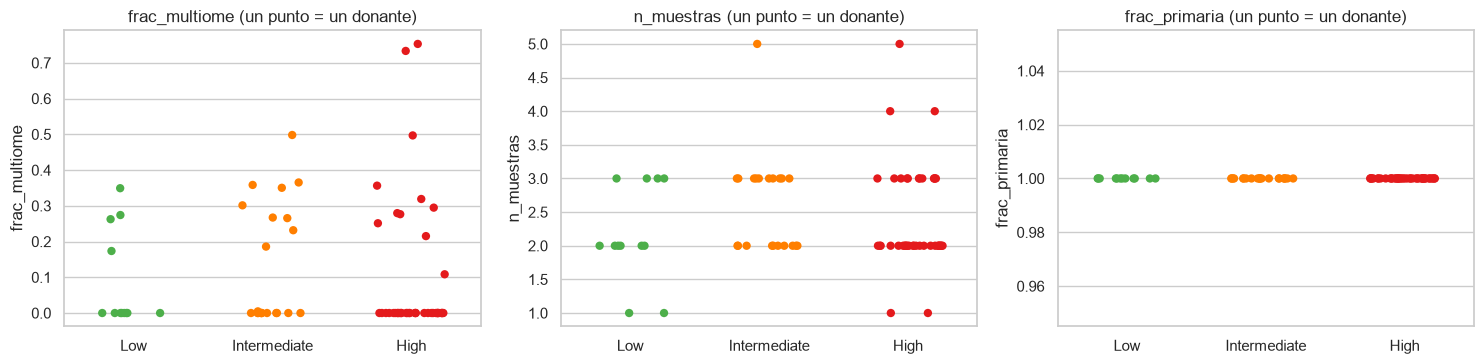

In [9]:
tec = obs[obs[LAB].isin(ORDEN)].groupby(DON, observed=True).agg(
    frac_multiome=("assay", lambda s: (s.astype(str) == "10x multiome").mean()),
    n_muestras=("Specimen ID", "nunique"),
    frac_primaria=("is_primary_data", "mean"))
tec[LAB] = tec.index.map(donantes[LAB]).astype(str)
res = []
for c in ["frac_multiome", "n_muestras", "frac_primaria"]:
    h, p = stats.kruskal(*[tec.loc[tec[LAB] == k, c] for k in ORDEN])
    res.append({"variable": c, "kruskal_H": h, "p": p, **{f"mediana_{k}": tec.loc[tec[LAB] == k, c].median() for k in ORDEN}})
tec_tabla = guardar(pd.DataFrame(res).set_index("variable"), "tecnicas_por_clase")
display(tec_tabla.round(3))

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axs, ["frac_multiome", "n_muestras", "frac_primaria"]):
    sns.stripplot(data=tec, x=LAB, y=c, order=ORDEN, palette=PALETA, ax=ax, size=6, jitter=0.25)
    ax.set_xlabel(""); ax.set_title(f"{c} (un punto = un donante)")
fig.tight_layout(); guardar_fig(fig, "tecnicas"); plt.show()

## 4. Composición de subtipos dentro de cada tipo celular

El subset fija cuántas células de cada **tipo** hay por clase (1.000), pero no qué **subtipos** (`Supertype`) hay
dentro de cada tipo. Si las células se muestrearon al azar dentro de cada donante, la proporción de supertipos de
cada donante refleja su composición real. El SEA-AD describe la pérdida de supertipos concretos con la progresión
(por ejemplo, algunos de Sst), así que aquí sí puede haber señal biológica.

Para cada supertipo, comparamos su proporción **por donante** entre las tres clases (Kruskal-Wallis) y corregimos por
comparaciones múltiples. Solo se consideran donante–tipo con al menos 10 células.

In [10]:
SUB = COL["supertype"]
comp = EDA.composition(obs[obs[LAB].isin(ORDEN)], DON, CT, SUB)
n_par = comp.groupby([DON, CT], observed=True)["n"].transform("sum")
comp = comp[n_par >= 10].copy()
comp[LAB] = comp[DON].map(donantes[LAB]).astype(str)
# rellenar con 0 los supertipos ausentes en un donante-tipo
ancho = comp.pivot_table(index=[DON, CT], columns=SUB, values="proporcion", fill_value=0, observed=True)
filas = []
for t in sorted(obs[CT].unique()):
    sub = ancho.xs(t, level=CT)
    sub = sub.loc[:, (sub > 0).mean() >= 0.2]                       # supertipos presentes en >= 20 % de donantes
    clase = sub.index.map(donantes[LAB]).astype(str)
    for st in sub.columns:
        grupos = [sub.loc[clase == c, st] for c in ORDEN]
        if min(len(g) for g in grupos) < 3:
            continue
        h, p = stats.kruskal(*grupos)
        rho = stats.spearmanr(pd.Series(clase).map({c: i for i, c in enumerate(ORDEN)}), sub[st].values)[0]
        filas.append({"tipo": t, "supertipo": st, "p": p, "rho_con_clase": rho,
                      **{f"media_{c}": g.mean() for c, g in zip(ORDEN, grupos)}})
st_tabla = pd.DataFrame(filas, columns=["tipo", "supertipo", "p", "rho_con_clase"] + [f"media_{c}" for c in ORDEN])
st_tabla["p_BH"] = multipletests(st_tabla["p"], method="fdr_bh")[1] if len(st_tabla) else []
st_tabla = guardar(st_tabla.sort_values("p").set_index(["tipo", "supertipo"]), "composicion_supertipos")
print(f"{len(st_tabla)} supertipos contrastados; con p_BH < 0,05: {int((st_tabla['p_BH'] < 0.05).sum())}")
display(st_tabla.head(15).round(3))

74 supertipos contrastados; con p_BH < 0,05: 0


p  rho_con_clase  media_Low  media_Intermediate  media_High   p_BH
tipo     supertipo                                                                                
L2IT-GLU L2/3 IT_10         0.001         -0.431      0.038               0.036       0.014  0.081
SST-GABA Sst_11             0.011         -0.369      0.029               0.020       0.010  0.251
MGC      Micro-PVM_3-SEAAD  0.012          0.280      0.104               0.082       0.175  0.251
SST-GABA Sst_2              0.018         -0.345      0.059               0.055       0.035  0.251
L2IT-GLU L6 IT Car3_1       0.018         -0.314      0.006               0.010       0.003  0.251
VIP-GABA Vip_2              0.020         -0.335      0.077               0.068       0.042  0.251
         Vip_6              0.040          0.299      0.030               0.034       0.059  0.375
SST-GABA Sst Chodl_2        0.041         -0.255      0.010               0.022       0.008  0.375
         Sst_22             0.054         -0.298      0.016               0.010       0.003  0.397
         Sst_20             0.056         -0.249      0.055               0.026       0.022  0.397
         Sst_19             0.062         -0.218      0.113               0.129       0.093  0.397
L2IT-GLU L6 IT Car3_3       0.069         -0.280      0.026               0.026       0.018  0.397
AST      Astro_3            0.070         -0.282      0.210               0.190       0.130  0.397
         Astro_2            0.077          0.273      0.548               0.584       0.677  0.406
VIP-GABA Vip_16             0.084         -0.265      0.022               0.018       0.015  0.416

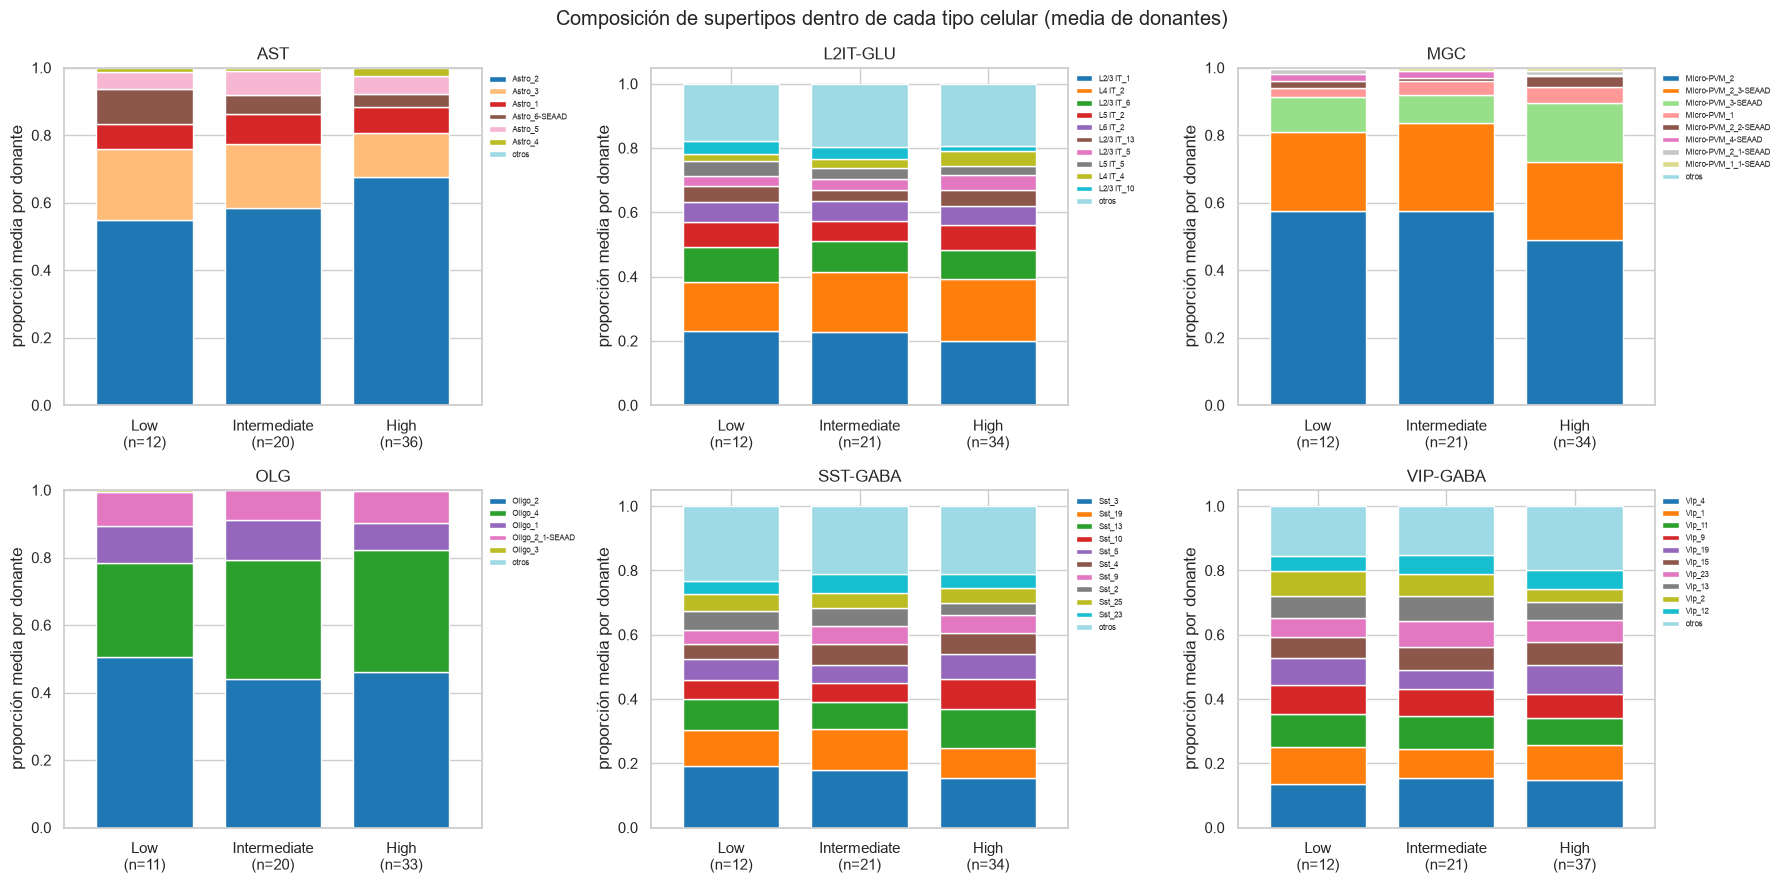

In [11]:
tipos = sorted(obs[CT].unique())
fig, axs = plt.subplots(2, 3, figsize=(18, 9))
for ax, t in zip(axs.ravel(), tipos):
    if t not in ancho.index.get_level_values(CT):
        ax.set_visible(False); continue
    sub = ancho.xs(t, level=CT)
    sub = sub.loc[:, sub.sum() > 0]                                 # solo los supertipos de este tipo
    medias = sub.groupby(sub.index.map(donantes[LAB]).astype(str)).mean()
    medias = medias.reindex([c for c in ORDEN if c in medias.index])  # clases sin donantes con >= 10 células: fuera
    medias = medias.loc[:, medias.mean().sort_values(ascending=False).index]
    principales = medias.columns[:10]
    medias = medias[principales].assign(otros=(1 - medias[principales].sum(1)).clip(lower=0))
    n_don = sub.index.map(donantes[LAB]).astype(str).value_counts().reindex(medias.index)
    medias.index = [f"{c}\n(n={n})" for c, n in n_don.items()]
    medias.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", width=0.75, legend=False)
    ax.set_title(t); ax.set_xlabel(""); ax.set_ylabel("proporción media por donante"); ax.tick_params(axis="x", rotation=0)
    ax.legend(fontsize=6, bbox_to_anchor=(1, 1), frameon=False)
fig.suptitle("Composición de supertipos dentro de cada tipo celular (media de donantes)")
fig.tight_layout(); guardar_fig(fig, "composicion_supertipos"); plt.show()

## 5. UMAP precalculado

El UMAP que trae el fichero (calculado por el SEA-AD sobre su embedding scVI, que corrige donante y lote). Los
puntos se dibujan en orden aleatorio para que ninguna clase tape a otra.

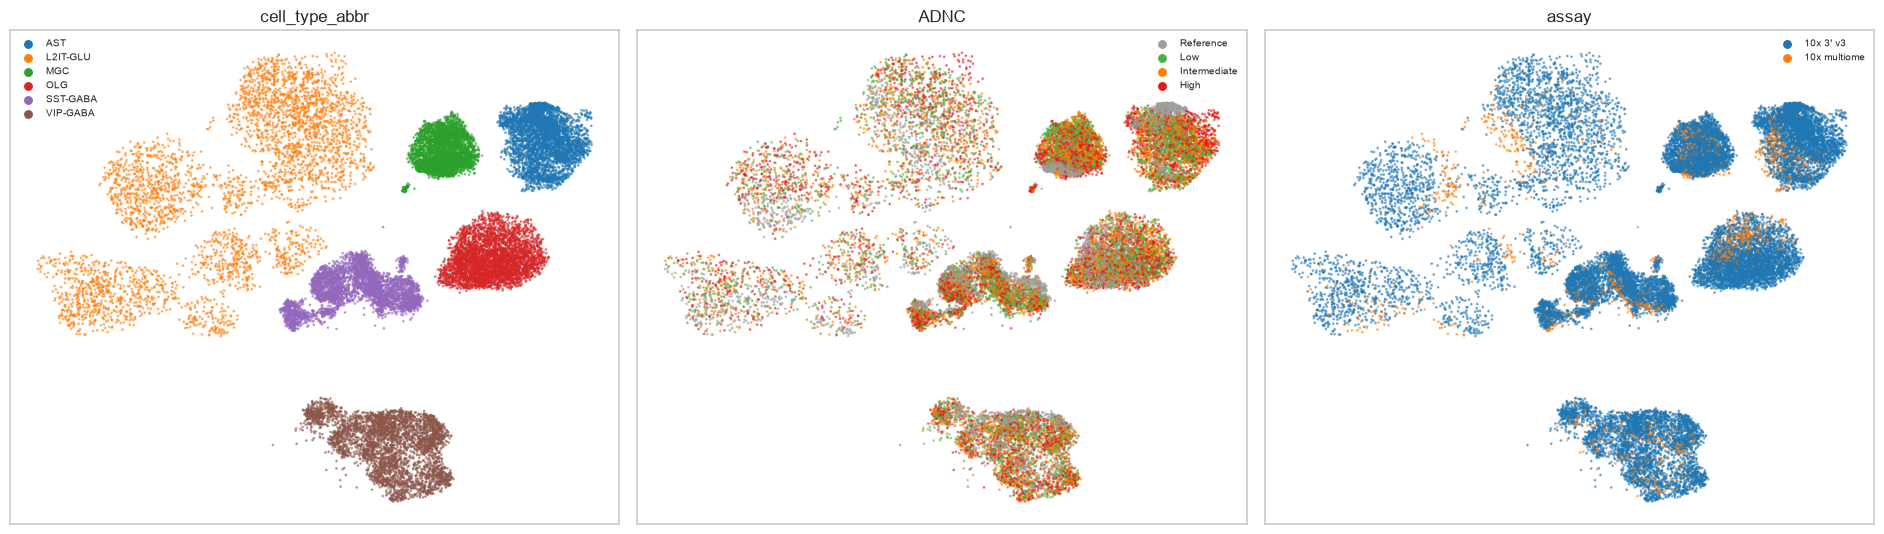

In [12]:
if umap is not None:
    orden_pts = np.random.default_rng(cfg["seed"]).permutation(len(obs))
    fig, axs = plt.subplots(1, 3, figsize=(19, 5.5))
    for ax, c in zip(axs, [CT, LAB, "assay"]):
        cats = obs[c].astype(str).values
        niveles = [x for x in TODAS if x in set(cats)] if c == LAB else sorted(set(cats))
        pal = PALETA if c == LAB else dict(zip(niveles, sns.color_palette("tab10", len(niveles))))
        ax.scatter(umap[orden_pts, 0], umap[orden_pts, 1], s=1, alpha=0.5, c=[pal[x] for x in cats[orden_pts]], rasterized=True)
        for x in niveles:
            ax.scatter([], [], color=pal[x], s=20, label=x)
        ax.legend(fontsize=7, markerscale=1.2, loc="best", frameon=False); ax.set_title(c); ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(); guardar_fig(fig, "umap"); plt.show()

In [13]:
resumen = {
    "donantes": int(len(d75)),
    "asociaciones_p": asoc["p"].round(4).to_dict(),
    "confusores_p_BH": asoc["p_BH"].dropna().round(4).to_dict(),
    "atipicas_MAD_pct_por_tipo": frac["atipica_MAD"].to_dict(),
    "atipicas_fijo_pct_por_tipo": frac["fuera_umbral_fijo"].to_dict(),
    "qc_por_clase_p_BH_min": qc_clase.groupby("metrica")["p_BH"].min().round(4).to_dict(),
    "tecnicas_p": tec_tabla["p"].round(4).to_dict(),
    "supertipos_significativos": st_tabla[st_tabla["p_BH"] < 0.05].reset_index()[["tipo", "supertipo", "rho_con_clase", "p_BH"]]
                                 .round(4).to_dict(orient="records"),
}
(TABLAS / "eda_resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False, default=str))

{
  "donantes": 75,
  "asociaciones_p": {
    "Thal phase": 0.0,
    "Braak stage": 0.0,
    "CERAD score": 0.0,
    "Cognitive status": 0.0021,
    "Continuous Pseudo-progression Score": 0.0,
    "edad_exacta": 0.1858,
    "Age at death": 0.5186,
    "sex": 0.251,
    "APOE4 status": 0.0047,
    "PMI": 0.8946,
    "Years of education": 0.5536,
    "self_reported_ethnicity": 0.6526,
    "LATE-NC stage": 0.0286,
    "Lewy body disease pathology": 0.0722,
    "Microinfarct pathology": 0.4613
  },
  "confusores_p_BH": {
    "edad_exacta": 0.4645,
    "Age at death": 0.692,
    "sex": 0.5019,
    "APOE4 status": 0.0471,
    "PMI": 0.8946,
    "Years of education": 0.692,
    "self_reported_ethnicity": 0.7252,
    "LATE-NC stage": 0.143,
    "Lewy body disease pathology": 0.2408,
    "Microinfarct pathology": 0.692
  },
  "atipicas_MAD_pct_por_tipo": {
    "OLG": 10.5,
    "MGC": 9.5,
    "AST": 12.6,
    "VIP-GABA": 7.8,
    "SST-GABA": 9.9,
    "L2IT-GLU": 10.7
  },
  "atipicas_fijo_pct_p